# ResearchIQ – Exploratory Data Analysis

**Name:** Chitra Vithoba Nayak
**Student ID:** MC2542
**Roll Number:** 42
**Subject:** Data Science and Advanced Analytics (DSAA)

## Objective

To perform exploratory data analysis on the original and fused
ResearchIQ datasets, assess data quality, identify statistical
patterns, analyse relationships between attributes and evaluate
the impact of data fusion.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path("../Datasets")

original_df = pd.read_csv(data_path / "database.csv")
fused_df = pd.read_csv(data_path / "dataset_fusion.csv")

print("Original Dataset:", original_df.shape)
print("Fused Dataset:", fused_df.shape)

Original Dataset: (601, 8)
Fused Dataset: (643, 61)


## 1. Dataset Exploration

Examine the structure, attributes, data types and sample
records of the original and fused datasets.

In [2]:
print("Original Dataset - First 5 Records")
display(original_df.head())

print("Fused Dataset - First 5 Records")
display(fused_df.head())

print("\nOriginal Dataset Attributes:")
print(original_df.columns.tolist())

print("\nFused Dataset Attributes:")
print(fused_df.columns.tolist())

print("\nOriginal Dataset Information:")
original_df.info()

print("\nFused Dataset Information:")
fused_df.info()

Original Dataset - First 5 Records


,Unnamed: 0,Id,title,link,year,authors,citations,abstract
0,0,0,Bargaining Game Based Time Scheduling Scheme f...,/document/9615057/,2021,['Sungwook Kim'],0,Backscatter communications have been acknowled...
1,1,1,The Use of Tangible User Interfaces in K12 Edu...,/document/9721879/,2022,"['José A. Gallud', 'Ricardo Tesoriero', 'Maria...",0,Tangible User Interfaces have enriched and exp...
2,2,2,Transient Surface Charge Characteristics of DC...,/document/9714376/,2022,"['Xiaolong Li', 'Songling Han', 'Mingde Wan', ...",0,The insulator in direct current gas-insulated ...
3,3,3,Electromagnetic Vibration Characteristics Anal...,/document/8918234/,2019,"['Defeng Kong', 'Zhijun Shuai', 'Wanyou Li', '...",3,Electromagnetic vibration is an important exci...
4,4,4,kNN-STUFF: kNN STreaming Unit for Fpgas,/document/8911384/,2019,"['João Vieira', 'Rui P. Duarte', 'Horácio C. N...",11,This paper presents kNN STreaming Unit For Fpg...


Fused Dataset - First 5 Records


,Id,title,link,year,authors,citations,abstract,doi,eid,source,...,supporting_paper_count,supporting_papers,text,timestamp,unnamed:_0,updated_date,url,usability,user_question,vote_count
0,D36790ecd55c2030d,360 Degree Panorama Synthesis From Sequential ...,/document/8926406/,2019,"['Dandan Zhu', 'Qiangqiang Zhou', 'Tian Han', ...",2,NaN,NaN,NaN,database,...,NaN,NaN,NaN,NaN,220.0,NaN,NaN,NaN,NaN,NaN
1,Da5abb1500bdeaef4,3D Large-Scale Point Cloud Semantic Segmentati...,/document/9291411/,2020,"['Jian Li', 'Quan Sun', 'Keru Chen', 'Hao Cui'...",2,Efficient semantic segmentation of large-scale...,NaN,NaN,database,...,NaN,NaN,NaN,NaN,407.0,NaN,NaN,NaN,NaN,NaN
2,D838f461c2fa673ce,4-D SLAM: An Efficient Dynamic Bayes Network-B...,/document/9279261/,2020,"['Zhongli Wang', 'Wenyi Li', 'Yan Shen', 'Baig...",1,Most of the existing simultaneous localization...,NaN,NaN,database,...,NaN,NaN,NaN,NaN,360.0,NaN,NaN,NaN,NaN,NaN
3,D377adeb4cd4096ad,A Boundary Assembling Method for Nested Biomed...,/document/9268950/,2020,"['Yanping Chen', 'Ying Hu', 'Yijing Li', 'Ruiz...",1,Biomedical named entity recognition (BNER) is ...,NaN,NaN,database,...,NaN,NaN,NaN,NaN,315.0,NaN,NaN,NaN,NaN,NaN
4,Df747870ae666c39b,A Case Study on the Monitor Mode Passive Captu...,/document/9610049/,2021,"['Ajay Prasad', 'Sourabh Singh Verma', 'Priyan...",0,Monitor mode packet capturing of WLAN is used ...,NaN,NaN,database,...,NaN,NaN,NaN,NaN,269.0,NaN,NaN,NaN,NaN,NaN



Original Dataset Attributes:
['Unnamed: 0', 'Id', 'title', 'link', 'year', 'authors', 'citations', 'abstract']

Fused Dataset Attributes:
['Id', 'title', 'link', 'year', 'authors', 'citations', 'abstract', 'doi', 'eid', 'source', 'topic', 'category', 'publication_name', 'document_type', 'dataset_id', 'dataset_title', 'dataset_description', 'dataset_url', 'pdf_url', 'pdf_path', 'action', 'answer', 'answer_format', 'answer_lines', 'cited_by_count', 'core_search_query', 'core_search_success', 'description', 'domain', 'download_count', 'experience_level', 'extracted_text', 'file_count', 'filename', 'id', 'limit', 'operation', 'owner', 'paper_rank', 'paper_title', 'programming_languages', 'publication_date', 'published_date', 'query', 'research_field', 'result', 'retrieved_paper_count', 'similarity_score', 'size', 'sort_by', 'status', 'supporting_paper_count', 'supporting_papers', 'text', 'timestamp', 'unnamed:_0', 'updated_date', 'url', 'usability', 'user_question', 'vote_count']

Origina

## 2. Data Quality Assessment

Compare the original and fused datasets based on record count,
attribute count, missing values and duplicate records.

In [3]:
def assess_quality(df):
    return {
        "Records": df.shape[0],
        "Attributes": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Missing Percentage": round(
            df.isnull().sum().sum() / df.size * 100, 2
        ),
        "Duplicate Records": df.duplicated().sum(),
        "Numeric Attributes": df.select_dtypes(
            include="number"
        ).shape[1]
    }

quality = pd.DataFrame({
    "Original Dataset": assess_quality(original_df),
    "Fused Dataset": assess_quality(fused_df)
})

display(quality)

,Original Dataset,Fused Dataset
Records,601.00,643.00
Attributes,8.00,61.00
Missing Values,50.00,28753.00
Missing Percentage,1.04,73.31
Duplicate Records,0.00,0.00
Numeric Attributes,4.00,16.00


## 3. Missing Value Analysis

Identify missing values in each attribute and compare
data completeness before and after data fusion.

Original Dataset


,Missing Count,Missing Percentage
abstract,50,8.32
Unnamed: 0,0,0.00
title,0,0.00
Id,0,0.00
link,0,0.00
year,0,0.00
authors,0,0.00
citations,0,0.00


Fused Dataset


,Missing Count,Missing Percentage
eid,643,100.00
core_search_success,642,99.84
answer_format,642,99.84
answer_lines,642,99.84
action,642,99.84
...,...,...
authors,2,0.31
year,0,0.00
title,0,0.00
Id,0,0.00


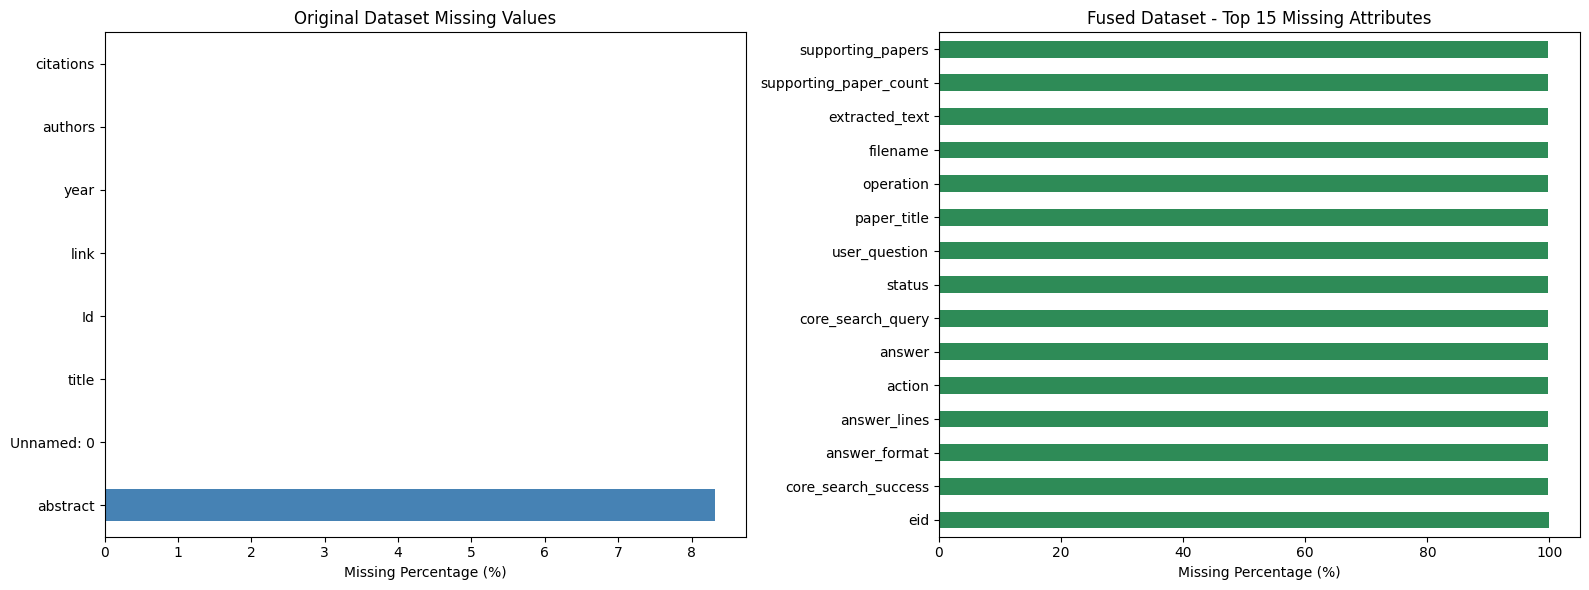

In [4]:
def missing_analysis(df):
    missing = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    return missing.sort_values(
        "Missing Percentage", ascending=False
    )

print("Original Dataset")
display(missing_analysis(original_df))

print("Fused Dataset")
display(missing_analysis(fused_df))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

missing_analysis(original_df)["Missing Percentage"].plot(
    kind="barh", ax=ax[0], color="steelblue"
)

missing_analysis(fused_df)["Missing Percentage"].head(15).plot(
    kind="barh", ax=ax[1], color="seagreen"
)

ax[0].set_title("Original Dataset Missing Values")
ax[1].set_title("Fused Dataset - Top 15 Missing Attributes")

for a in ax:
    a.set_xlabel("Missing Percentage (%)")

plt.tight_layout()
plt.show()

## 4. Descriptive Statistics

Calculate summary statistics for numerical and categorical
attributes to understand data distribution, central tendency
and variability.

In [5]:
print("Original Dataset - Numerical Statistics")
display(original_df.describe().T)

print("Fused Dataset - Numerical Statistics")
display(fused_df.describe().T)

print("Original Dataset - Categorical Statistics")
display(original_df.describe(include=["object", "string"]).T)

print("Fused Dataset - Categorical Statistics")
display(fused_df.describe(include=["object", "string"]).T)

Original Dataset - Numerical Statistics


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,601.0,300.000000,173.638033,0.0,150.0,300.0,450.0,600.0
Id,601.0,300.000000,173.638033,0.0,150.0,300.0,450.0,600.0
year,601.0,2020.534110,1.136919,2019.0,2019.0,2021.0,2022.0,2022.0
citations,601.0,1.998336,5.163493,0.0,0.0,0.0,2.0,49.0


Fused Dataset - Numerical Statistics


,count,mean,std,min,25%,50%,75%,max
year,643.0,2.020580e+03,1.509381e+00,2008.0000,2019.0000,2021.000000,2.022000e+03,2.026000e+03
eid,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer_lines,1.0,1.000000e+00,NaN,1.0000,1.0000,1.000000,1.000000e+00,1.000000e+00
cited_by_count,10.0,1.871100e+03,1.597340e+03,906.0000,965.2500,1036.000000,1.891500e+03,5.358000e+03
download_count,19.0,9.209658e+04,1.052567e+05,2854.0000,15636.0000,35172.000000,1.376735e+05,3.681760e+05
file_count,19.0,0.000000e+00,0.000000e+00,0.0000,0.0000,0.000000,0.000000e+00,0.000000e+00
id,601.0,3.000000e+02,1.736380e+02,0.0000,150.0000,300.000000,4.500000e+02,6.000000e+02
limit,19.0,1.000000e+01,0.000000e+00,10.0000,10.0000,10.000000,1.000000e+01,1.000000e+01
paper_rank,11.0,6.000000e+00,3.316625e+00,1.0000,3.5000,6.000000,8.500000e+00,1.100000e+01
retrieved_paper_count,11.0,1.100000e+01,0.000000e+00,11.0000,11.0000,11.000000,1.100000e+01,1.100000e+01


Original Dataset - Categorical Statistics


,count,unique,top,freq
title,601,601,Bargaining Game Based Time Scheduling Scheme f...,1
link,601,601,/document/9615057/,1
authors,601,600,['Norifumi Kamiya'],2
abstract,551,551,Backscatter communications have been acknowled...,1


Fused Dataset - Categorical Statistics


,count,unique,top,freq
Id,643,643,D36790ecd55c2030d,1
title,643,643,360 Degree Panorama Synthesis From Sequential ...,1
link,631,631,/document/8926406/,1
authors,641,638,Iqbal H. Sarker,2
citations,630,55,0,364
abstract,589,589,Efficient semantic segmentation of large-scale...,1
doi,10,10,10.1007/s42979-022-01043-x,1
source,643,6,database,601
topic,42,6,brain disease,11
category,40,11,All,19


## 5. Univariate Analysis

Analyse individual numerical attributes using histograms
and boxplots to understand distributions, variability
and potential outliers.

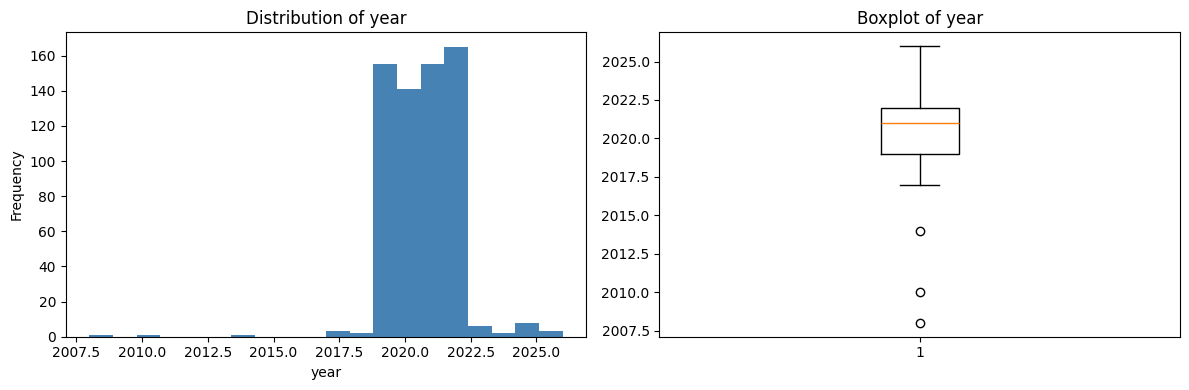

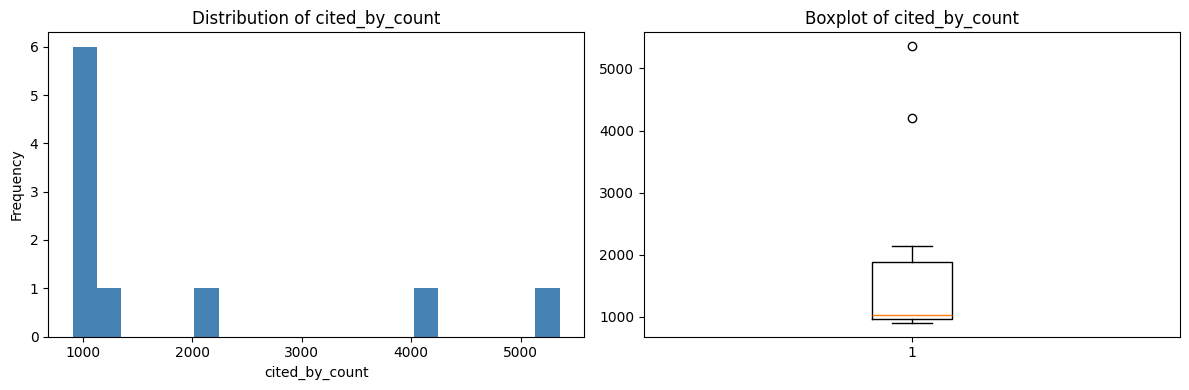

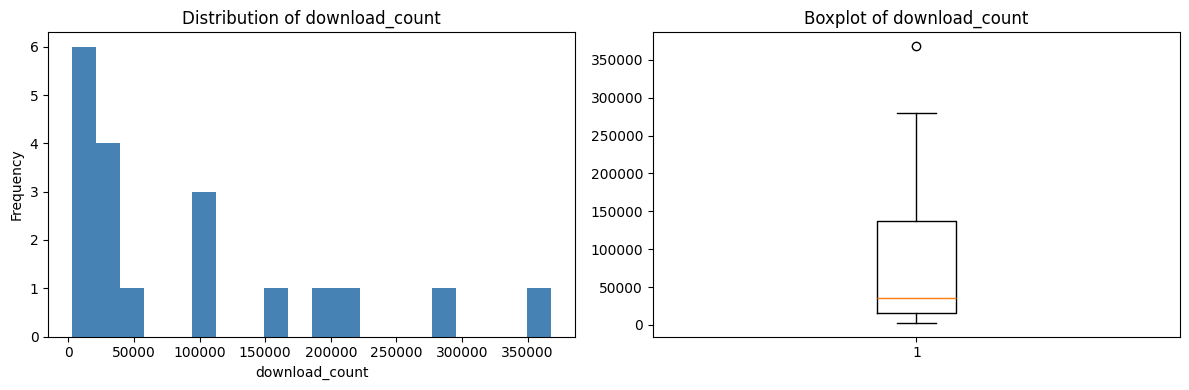

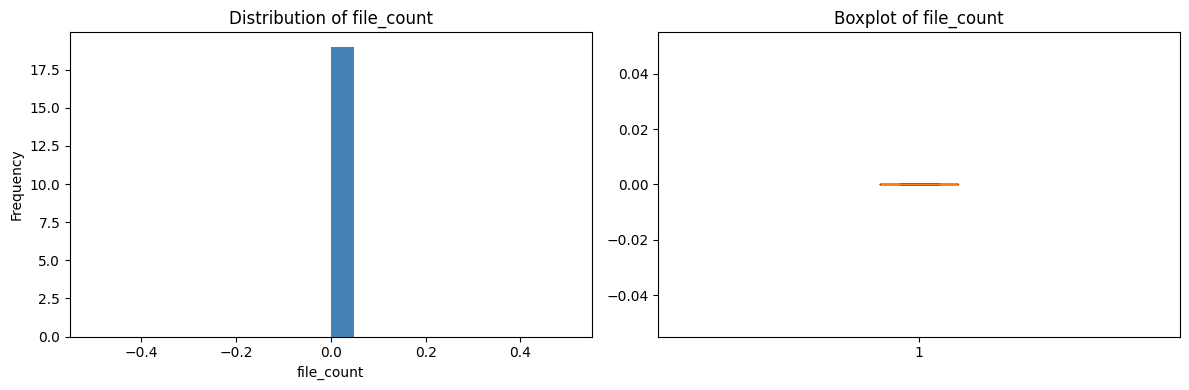

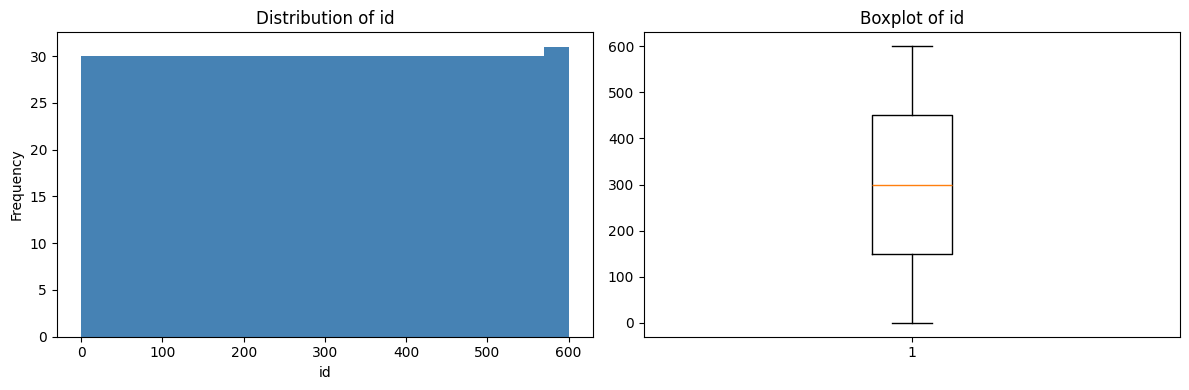

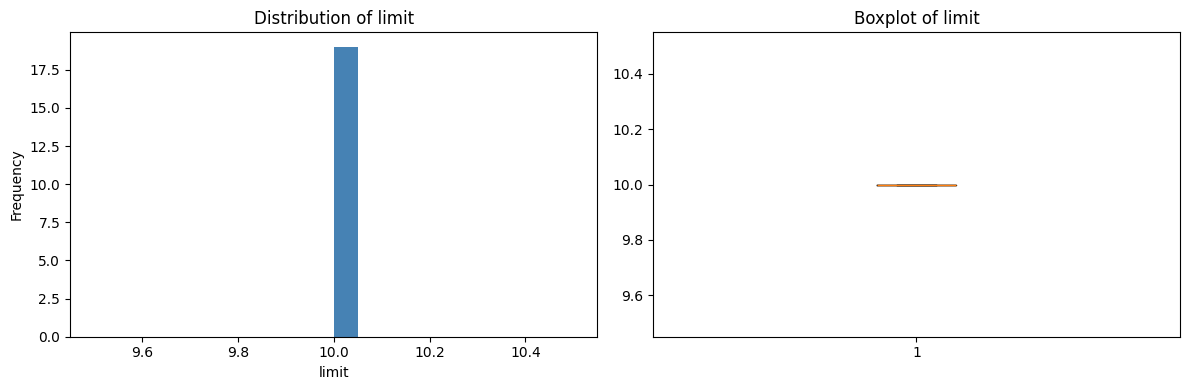

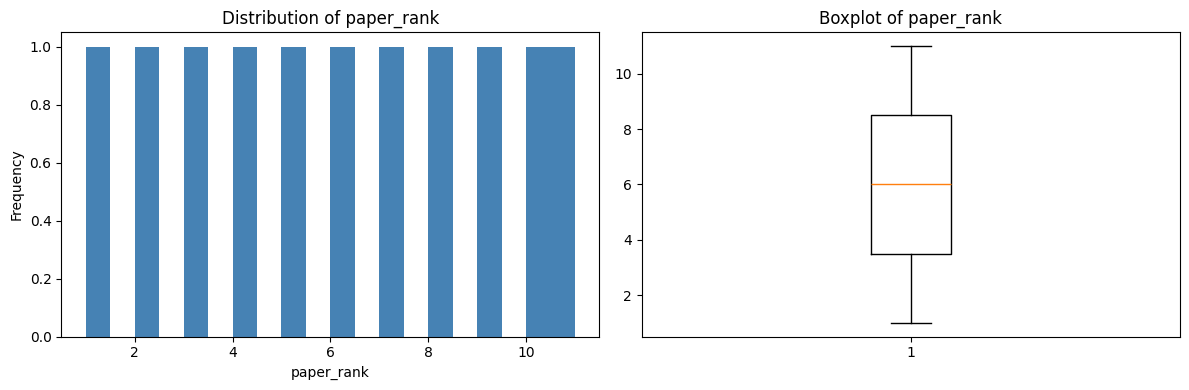

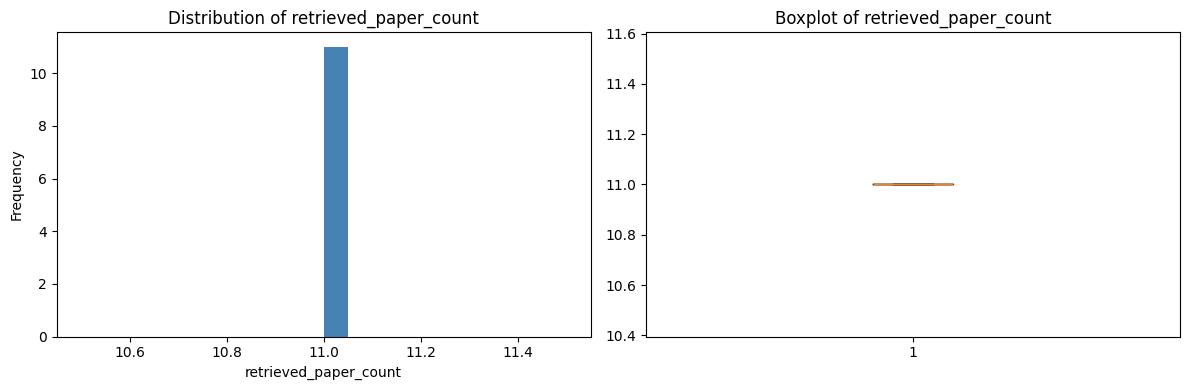

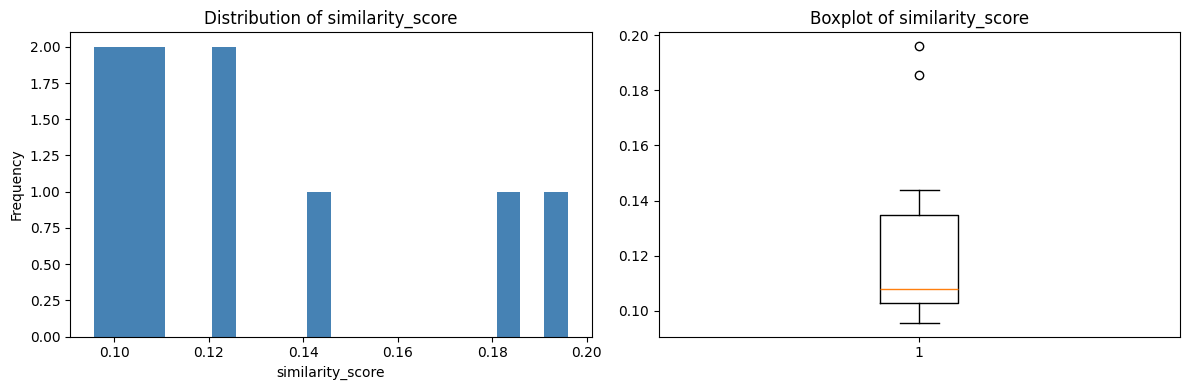

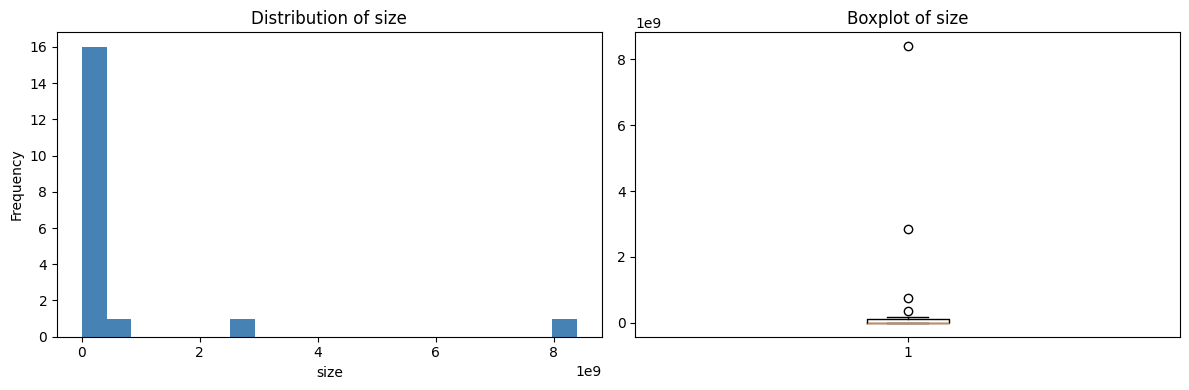

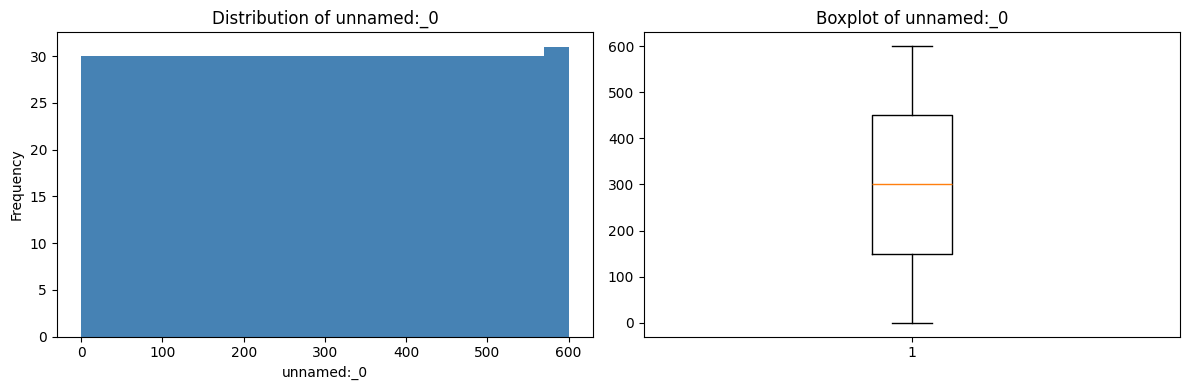

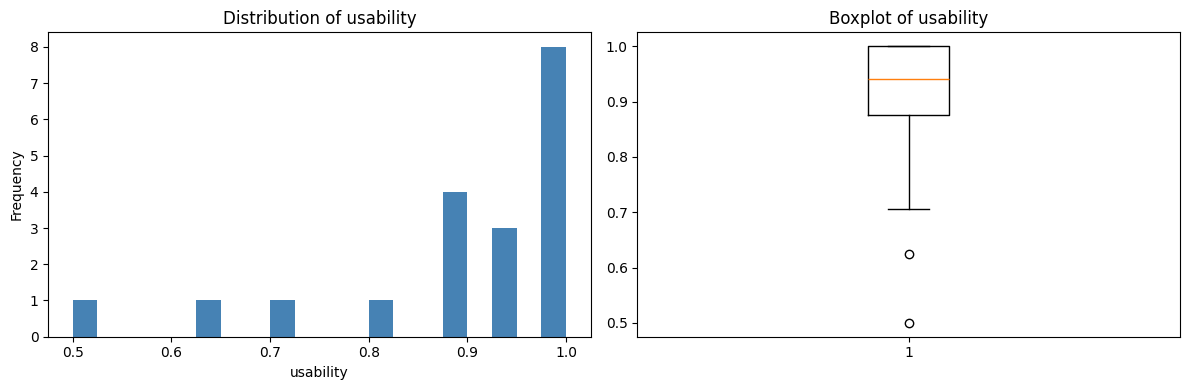

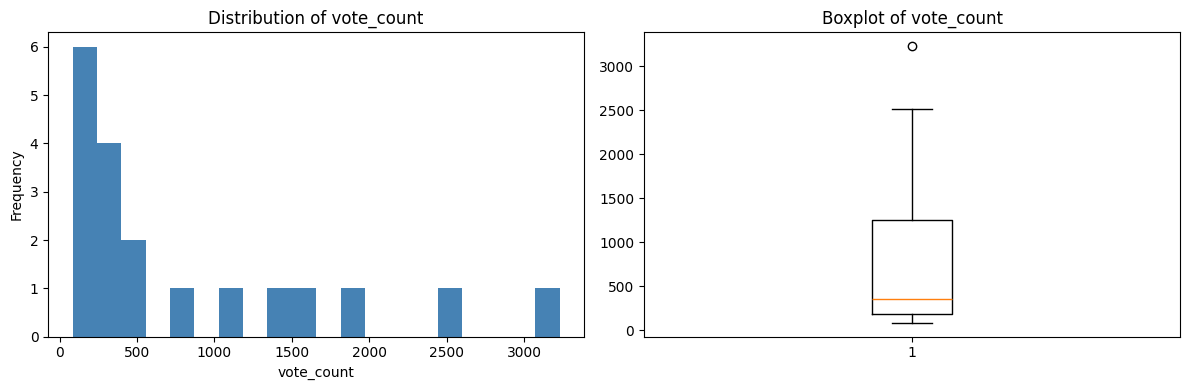

In [6]:
numeric = fused_df.select_dtypes(include="number")
numeric = numeric.drop(
    columns=["Unnamed: 0"], errors="ignore"
)

for col in numeric.columns:
    values = numeric[col].dropna()

    if len(values) < 2:
        continue

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].hist(values, bins=20, color="steelblue")
    ax[0].set_title(f"Distribution of {col}")
    ax[0].set_xlabel(col)
    ax[0].set_ylabel("Frequency")

    ax[1].boxplot(values)
    ax[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

## 6. Bivariate Analysis

Examine relationships between two numerical attributes
using scatter plots and correlation coefficients.

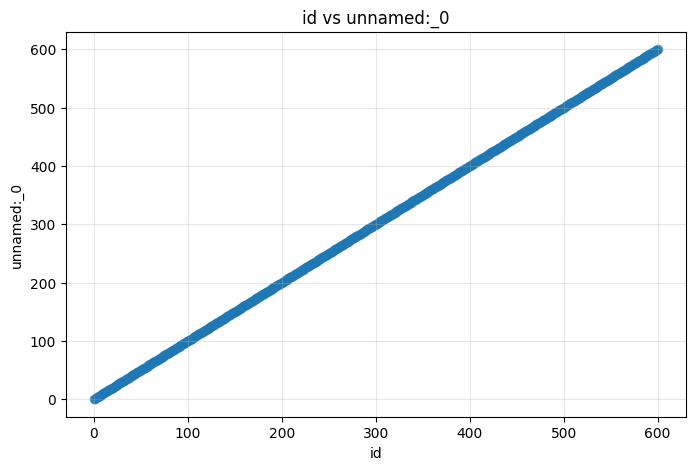

Correlation: 1.0000
Valid paired records: 601


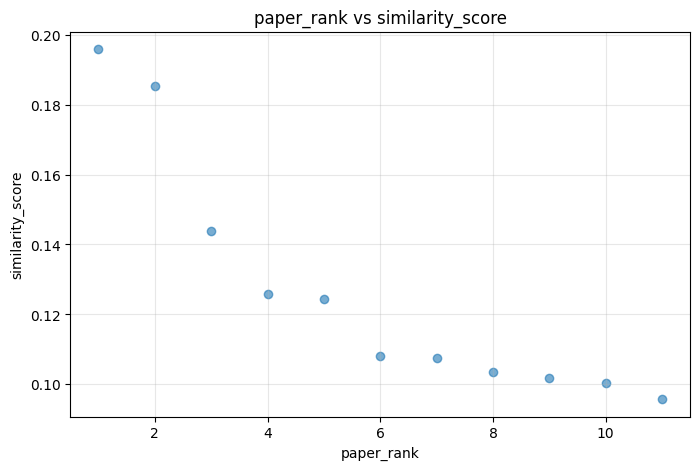

Correlation: -0.8926
Valid paired records: 11


In [8]:
numeric = fused_df.select_dtypes(include="number")
numeric = numeric.drop(columns=["Unnamed: 0"], errors="ignore")

pairs = []

for i, col1 in enumerate(numeric.columns):
    for col2 in numeric.columns[i + 1:]:
        data = numeric[[col1, col2]].dropna()

        if len(data) >= 10:
            if data[col1].nunique() < 2 or data[col2].nunique() < 2:
                continue

            correlation = data[col1].corr(data[col2])

            if pd.notna(correlation):
                pairs.append((col1, col2, correlation))

pairs.sort(key=lambda x: abs(x[2]), reverse=True)

for col1, col2, correlation in pairs[:2]:
    data = numeric[[col1, col2]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(data[col1], data[col2], alpha=0.6)
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.title(f"{col1} vs {col2}")
    plt.grid(alpha=0.3)
    plt.show()

    print(f"Correlation: {correlation:.4f}")
    print(f"Valid paired records: {len(data)}")

## 7. Multivariate Analysis

Analyse relationships among multiple numerical attributes
using a correlation matrix and heatmap to identify positive
and negative associations.

,year,cited_by_count,download_count,id,paper_rank,similarity_score,size,unnamed:_0,usability,vote_count
year,1.00,0.41,-0.25,-0.07,-0.49,0.48,0.02,-0.07,0.24,-0.26
cited_by_count,0.41,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
download_count,-0.25,NaN,1.00,NaN,NaN,NaN,-0.24,NaN,-0.07,0.88
id,-0.07,NaN,NaN,1.00,NaN,NaN,NaN,1.00,NaN,NaN
paper_rank,-0.49,NaN,NaN,NaN,1.00,-0.89,NaN,NaN,NaN,NaN
similarity_score,0.48,NaN,NaN,NaN,-0.89,1.00,NaN,NaN,NaN,NaN
size,0.02,NaN,-0.24,NaN,NaN,NaN,1.00,NaN,-0.26,-0.21
unnamed:_0,-0.07,NaN,NaN,1.00,NaN,NaN,NaN,1.00,NaN,NaN
usability,0.24,NaN,-0.07,NaN,NaN,NaN,-0.26,NaN,1.00,-0.06
vote_count,-0.26,NaN,0.88,NaN,NaN,NaN,-0.21,NaN,-0.06,1.00


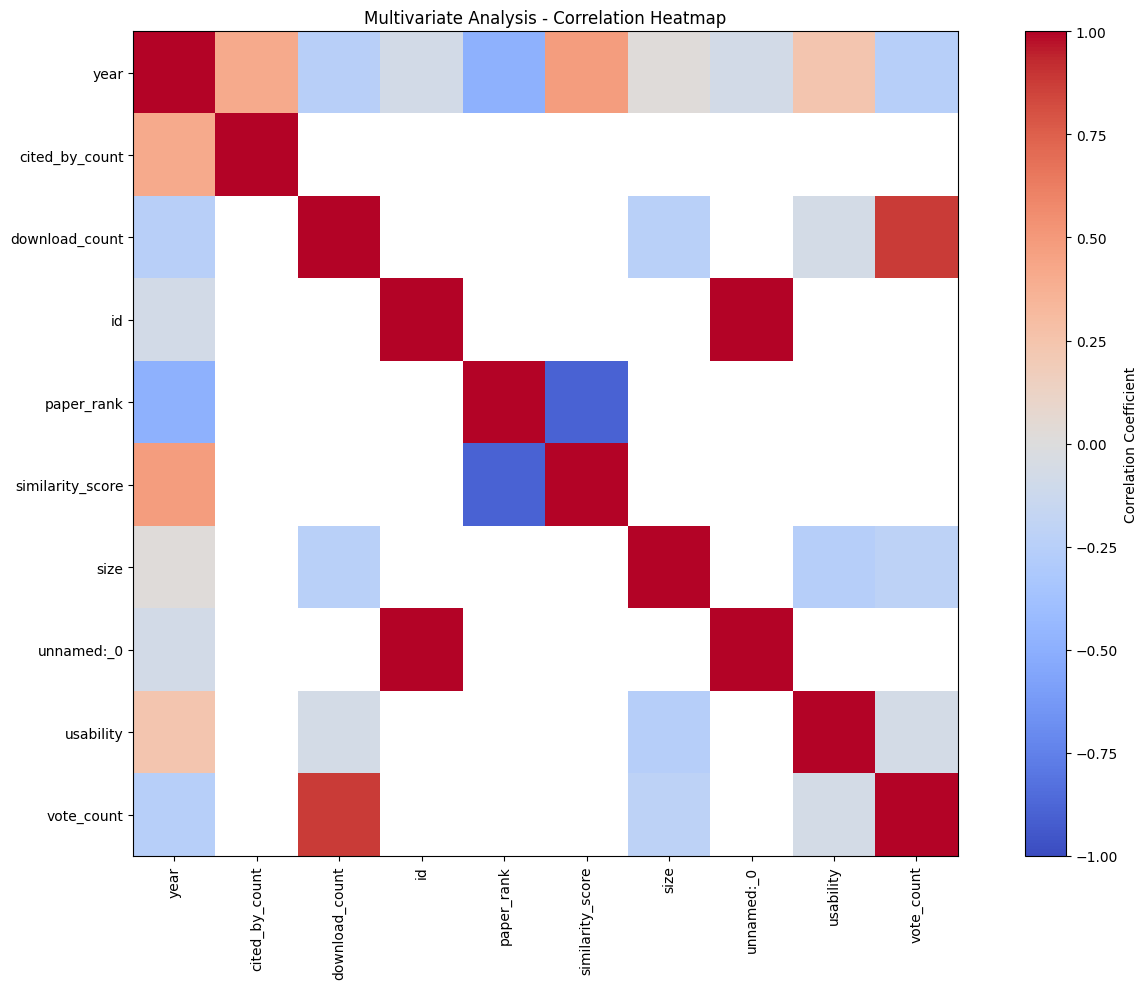

In [9]:
numeric = fused_df.select_dtypes(include="number")
numeric = numeric.drop(columns=["Unnamed: 0"], errors="ignore")

# Exclude constant attributes
numeric = numeric.loc[:, numeric.nunique() > 1]

correlation_matrix = numeric.corr(min_periods=10)

display(correlation_matrix.round(2))

plt.figure(figsize=(14, 10))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Multivariate Analysis - Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Outlier Detection Using IQR

Identify potential outliers using the Interquartile Range
(IQR) method. Outliers are retained because extreme values
may represent valid research observations rather than errors.

In [10]:
outlier_results = []

for col in numeric.columns:
    values = numeric[col].dropna()

    if len(values) < 10:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = values[(values < lower) | (values > upper)]

    outlier_results.append({
        "Attribute": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(values) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Attribute,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,year,2019.00,2.022000e+03,3.000000e+00,2.014500e+03,2.026500e+03,3,0.47
1,cited_by_count,965.25,1.891500e+03,9.262500e+02,-4.241200e+02,3.280880e+03,2,20.00
2,download_count,15636.00,1.376735e+05,1.220375e+05,-1.674202e+05,3.207298e+05,1,5.26
3,id,150.00,4.500000e+02,3.000000e+02,-3.000000e+02,9.000000e+02,0,0.00
4,paper_rank,3.50,8.500000e+00,5.000000e+00,-4.000000e+00,1.600000e+01,0,0.00
5,similarity_score,0.10,1.300000e-01,3.000000e-02,5.000000e-02,1.800000e-01,2,18.18
6,size,5196.00,1.278362e+08,1.278310e+08,-1.917414e+08,3.195828e+08,4,21.05
7,unnamed:_0,150.00,4.500000e+02,3.000000e+02,-3.000000e+02,9.000000e+02,0,0.00
8,usability,0.88,1.000000e+00,1.200000e-01,6.900000e-01,1.190000e+00,2,10.53
9,vote_count,184.50,1.252500e+03,1.068000e+03,-1.417500e+03,2.854500e+03,1,5.26


## 9. Before-and-After Fusion Comparison

Compare the original and fused datasets to evaluate changes
in record count, attribute coverage, data completeness
and analytical opportunities introduced by data fusion.

,Original Dataset,Fused Dataset,Change
Records,601.00,643.00,42.00
Attributes,8.00,61.00,53.00
Missing Values,50.00,28753.00,28703.00
Missing Percentage,1.04,73.31,72.27
Duplicate Records,0.00,0.00,0.00
Numeric Attributes,4.00,16.00,12.00


New Attributes After Fusion: 54
action
answer
answer_format
answer_lines
category
cited_by_count
core_search_query
core_search_success
dataset_description
dataset_id
dataset_title
dataset_url
description
document_type
doi
domain
download_count
eid
experience_level
extracted_text
file_count
filename
id
limit
operation
owner
paper_rank
paper_title
pdf_path
pdf_url
programming_languages
publication_date
publication_name
published_date
query
research_field
result
retrieved_paper_count
similarity_score
size
sort_by
source
status
supporting_paper_count
supporting_papers
text
timestamp
topic
unnamed:_0
updated_date
url
usability
user_question
vote_count


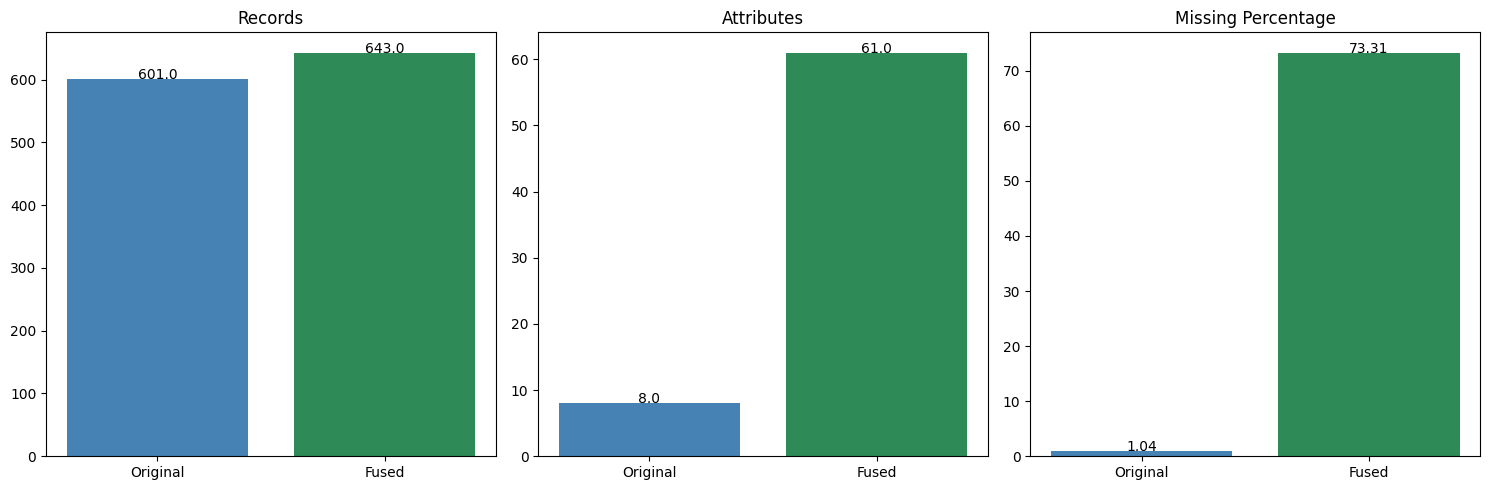

In [11]:
comparison = quality.copy()

comparison["Change"] = (
    comparison["Fused Dataset"] -
    comparison["Original Dataset"]
)

display(comparison)

new_attributes = sorted(
    set(fused_df.columns) - set(original_df.columns)
)

print("New Attributes After Fusion:", len(new_attributes))

for col in new_attributes:
    print(col)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["Records", "Attributes", "Missing Percentage"]

for i, metric in enumerate(metrics):
    ax[i].bar(
        ["Original", "Fused"],
        quality.loc[metric],
        color=["steelblue", "seagreen"]
    )

    ax[i].set_title(metric)

    for j, value in enumerate(quality.loc[metric]):
        ax[i].text(j, value, str(round(value, 2)), ha="center")

plt.tight_layout()
plt.show()

## 10. Key Findings and Conclusion

### Key Findings

1. Data fusion increased the dataset from 601 to 643 records,
   expanding the available research information.

2. The number of columns increased from 8 to 61, including
   additional attributes collected from external APIs.

3. Missing values increased after fusion because different
   data sources provide different types of information.

4. Univariate, bivariate and multivariate analyses helped
   examine distributions and relationships between attributes.

5. The IQR method identified potential outliers, which were
   retained to preserve potentially valid research observations.

### Conclusion

The exploratory data analysis demonstrates how data fusion
expands the analytical capabilities of ResearchIQ. The fused
dataset provides additional opportunities for statistical
analysis, research discovery and interactive visualization.

However, source-specific missing values and potential outliers
must be considered when interpreting the results.

In [12]:
print("Exploratory Data Analysis Completed")
display(quality)

Exploratory Data Analysis Completed


,Original Dataset,Fused Dataset
Records,601.00,643.00
Attributes,8.00,61.00
Missing Values,50.00,28753.00
Missing Percentage,1.04,73.31
Duplicate Records,0.00,0.00
Numeric Attributes,4.00,16.00
